In [1]:
import os, time, json, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
 
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_ROOT = "./data"
OUT = "./q2_outputs"          # inside GitHub repo
for sub in ("figures", "gifs", "checkpoints", "results", "tables"):
    os.makedirs(os.path.join(OUT, sub), exist_ok=True)
torch.backends.cudnn.benchmark = True
 
def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
 
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
import platform; print("CPU:", platform.processor() or platform.machine())

torch 2.14.0+cu132 | torchvision 0.29.1+cu132 | device: cuda
GPU: NVIDIA GeForce RTX 2060
CPU: Intel64 Family 6 Model 165 Stepping 2, GenuineIntel


In [2]:
# Data: All 10,000 videos, split by video index
ds = torchvision.datasets.MovingMNIST(root=DATA_ROOT, split=None, download=True)
VIDEOS_U8 = ds.data                     # uint8, (10000, 20, 1, 64, 64)
assert VIDEOS_U8.shape == (10000, 20, 1, 64, 64) and VIDEOS_U8.dtype == torch.uint8
 
TRAIN_U8 = VIDEOS_U8[:8000]             # videos 0-7999
VAL_U8   = VIDEOS_U8[8000:9000]         # videos 8000-8999
TEST_U8  = VIDEOS_U8[9000:10000]        # videos 9000-9999
 
def to_float(v):
    """float32 in [0, 1]. Applied per batch: identical to converting the whole
    dataset up front, but avoids holding 3.3 GB of float32 frames in memory."""
    return v.float() / 255.0
 
TRAIN_DEV = TRAIN_U8.to(DEVICE)
VAL_DEV   = VAL_U8.to(DEVICE)
TEST_DEV  = TEST_U8.to(DEVICE)
print(TRAIN_DEV.shape, VAL_DEV.shape, TEST_DEV.shape)

torch.Size([8000, 20, 1, 64, 64]) torch.Size([1000, 20, 1, 64, 64]) torch.Size([1000, 20, 1, 64, 64])


In [3]:
# Transformations (mirror, rotation, 8 symmetries) and windows
def M(x):
    """Mirror: (Mx)[i, j] = x[i, 63 - j]  (flip the column axis)."""
    return x.flip(-1)
 
def R(x, a=1):
    """Rotation by a quarter-turns anticlockwise."""
    return torch.rot90(x, k=a, dims=(-2, -1))
 
# Group element g = (a, m):  m = 0 -> R^a,  m = 1 -> M R^a  (rotate --> mirror)
G = [(a, m) for m in (0, 1) for a in range(4)]
G_NAMES = {(a, m): ("M" if m else "") + (f"R^{a}" if (a or not m) else "") for a, m in G}
 
def apply_g(x, g):
    a, m = g
    y = R(x, a)
    return M(y) if m else y
 
def invert_g(x, g):
    """R^a has inverse R^-a; every M R^a is its own inverse."""
    a, m = g
    return apply_g(x, g) if m else R(x, -a)
 
N_FRAMES = 20
STARTS_NORMAL = {1: list(range(1, 12))}                                     # models A, B
STARTS_AUG = {1: list(range(1, 15)), 2: list(range(1, 9)), 3: [1, 2]}       # models C, D
 
def make_windows(videos, t, k):
    """videos: (B, 20, C, H, W).  t, k: ints or LongTensors of shape (B,), frames 1-based.
    Returns X (B,5,C,H,W), Y (B,5,C,H,W) with non-existent targets zero-filled,
    and valid (B,5) bool marking target frames that exist (frame number <= 20)."""
    B, dev = videos.shape[0], videos.device
    t = torch.as_tensor(t, device=dev).long().expand(B) if not torch.is_tensor(t) or t.dim() == 0 \
        else t.to(dev).long()
    k = torch.as_tensor(k, device=dev).long().expand(B) if not torch.is_tensor(k) or k.dim() == 0 \
        else k.to(dev).long()
    j = torch.arange(5, device=dev)
    in_idx = (t[:, None] - 1) + j[None] * k[:, None]           # 0-based frame indices
    out_idx = (t[:, None] - 1) + (5 + j[None]) * k[:, None]
    valid = out_idx <= N_FRAMES - 1
    assert (in_idx <= N_FRAMES - 1).all(), "all five input frames must exist"
    assert valid[:, :2].all(), "at least two target frames must exist"
    b = torch.arange(B, device=dev)[:, None]
    X = videos[b, in_idx]
    Y = videos[b, out_idx.clamp(max=N_FRAMES - 1)]
    Y = Y * valid[..., None, None, None].to(Y.dtype)
    return X, Y, valid

In [4]:
# Table 1: checks on synthetic tensors (uses same functions as experiments)
def fmt(v):
    """3 significant figures; scientific notation below 1e-3."""
    v = float(v)
    if v == 0:
        return "0"
    if abs(v) < 1e-3:
        return f"{v:.2e}"
    s = f"{v:#.3g}"
    return s[:-1] if s.endswith(".") else s
 
def latex_table(header, rows, caption, label):
    cols = "l" * len(header)
    lines = [r"\begin{table}[H]", r"\centering\small", rf"\begin{{tabular}}{{{cols}}}", r"\toprule",
             " & ".join(header) + r" \\", r"\midrule"]
    lines += [" & ".join(str(c) for c in r) + r" \\" for r in rows]
    lines += [r"\bottomrule", r"\end{tabular}", rf"\caption{{{caption}}}", rf"\label{{{label}}}", r"\end{table}"]
    return "\n".join(lines)
 
torch.manual_seed(0); x = torch.rand(20, 1, 64, 64)
p = torch.zeros(20, 1, 64, 64); p[7, 0, 10, 20] = 1
 
def maxdiff(a, b):
    return (a - b).abs().max().item()
 
def bright(v):
    f, _, r, c = (v == 1).nonzero()[0].tolist()
    return f"({f}, {r}, {c})"
 
rows = []
lhs = M(M(x));      rows.append(["(a) $\\max|M(M(x)) - x|$", "0", f"{maxdiff(lhs, x):g} (torch.equal: {torch.equal(lhs, x)})"])
lhs = R(x, 4);      rows.append(["(b) $\\max|R^4(x) - x|$", "0", f"{maxdiff(lhs, x):g} (torch.equal: {torch.equal(lhs, x)})"])
lhs = M(R(M(x)))    # MRM(x): mirror, then rotate, then mirror
rhs = R(x, -1)
rows.append(["(c) $\\max|MRM(x) - R^{-1}(x)|$", "0", f"{maxdiff(lhs, rhs):g} (torch.equal: {torch.equal(lhs, rhs)})"])
rows.append(["(d) bright pixel of $M(p)$", "(7, 10, 43)", bright(M(p))])
rows.append(["(e) bright pixel of $R(p)$", "(7, 43, 10)", bright(R(p))])
 
numbered = torch.arange(1, 21, dtype=torch.float32).view(20, 1, 1, 1).expand(20, 1, 64, 64).clone()
expected = {1: "1--5 / 6--10", 2: "1, 3, 5, 7, 9 / 11, 13, 15, 17, 19", 3: "1, 4, 7, 10, 13 / 16, 19"}
for label, k in (("(f)", 1), ("(g)", 2), ("(h)", 3)):
    X, Y, valid = make_windows(numbered[None], 1, k)
    xin = [int(v) for v in X[0, :, 0, 0, 0].tolist()]
    yout = [int(v) for v in Y[0, valid[0], 0, 0, 0].tolist()]
    # sanity: every pixel of a returned frame carries the same frame number
    assert (X[0] == X[0, :, :1, :1, :1]).all() and (Y[0, valid[0]] == Y[0, valid[0], :1, :1, :1]).all()
    rows.append([f"{label} {k}$\\times$ input / target frames", expected[k],
                 ", ".join(map(str, xin)) + " / " + ", ".join(map(str, yout))])
 
for r in rows:
    print(f"{r[0]:<45} expected {r[1]:<40} yours {r[2]}")
assert all(r[2].startswith("0 ") for r in rows[:3]), "checks (a)-(c) failed"
assert rows[3][2] == "(7, 10, 43)" and rows[4][2] == "(7, 43, 10)", "checks (d)-(e) failed"
tex = latex_table(["Check", "Expected", "Yours"], rows,
                  "Implementation checks on synthetic tensors.", "tab:q2-1")
open(f"{OUT}/tables/table1.tex", "w").write(tex)

(a) $\max|M(M(x)) - x|$                       expected 0                                        yours 0 (torch.equal: True)
(b) $\max|R^4(x) - x|$                        expected 0                                        yours 0 (torch.equal: True)
(c) $\max|MRM(x) - R^{-1}(x)|$                expected 0                                        yours 0 (torch.equal: True)
(d) bright pixel of $M(p)$                    expected (7, 10, 43)                              yours (7, 10, 43)
(e) bright pixel of $R(p)$                    expected (7, 43, 10)                              yours (7, 43, 10)
(f) 1$\times$ input / target frames           expected 1--5 / 6--10                             yours 1, 2, 3, 4, 5 / 6, 7, 8, 9, 10
(g) 2$\times$ input / target frames           expected 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19       yours 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19
(h) 3$\times$ input / target frames           expected 1, 4, 7, 10, 13 / 16, 19                 yours 1, 4, 7, 10, 13 / 16, 19


789

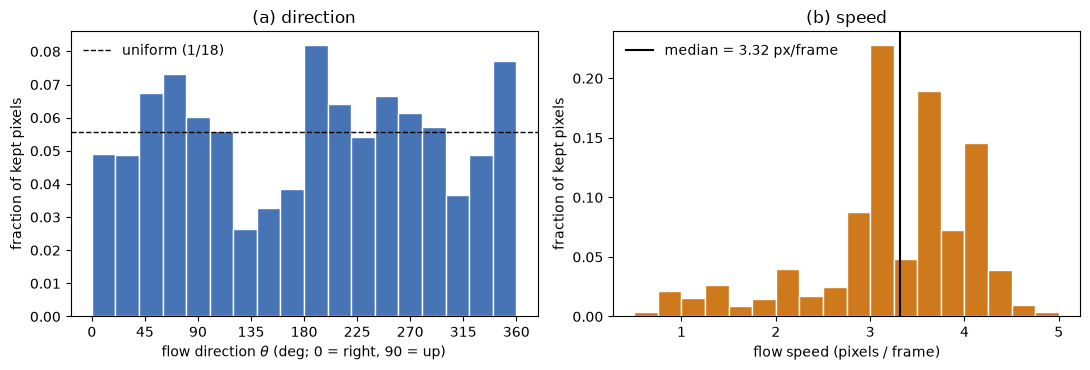

Pixels kept: 103050   median speed: 3.318 px/frame  -> 2x: 6.64, 3x: 9.95 px/frame
speed percentiles 10/25/75/90/99: [2.14 3.   3.89 4.12 4.67]
direction histogram (fraction per 20-deg bin): [0.049  0.0488 0.0675 0.0731 0.0602 0.0561 0.0263 0.0326 0.0384 0.082
 0.0642 0.0541 0.0666 0.0614 0.0571 0.0366 0.0487 0.0772]
max / min bin relative to uniform: 1.475 0.474
TV distance histogram vs its mirror image (theta -> 180 - theta): 0.1322
TV distance histogram vs its 90-deg rotation (theta -> theta + 90): 0.2


In [5]:
# Figure 1: optical-flow statistics of first 50 training videos
import cv2
 
angles, speeds = [], []
for v in range(50):
    # The stored uint8 frames are exactly round(255 * x) for the float frames x in [0, 1].
    vid = TRAIN_U8[v, :, 0].numpy()
    for s in range(19):                                  # pairs (x_s, x_{s+1}), s = 1..19
        prev, nxt = vid[s], vid[s + 1]
        flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        dx, dy = flow[..., 0], flow[..., 1]
        mag = np.sqrt(dx ** 2 + dy ** 2)
        keep = (prev > 51) & (nxt > 51) & (mag > 0.5)    # intensity > 0.2 in both frames
        angles.append(np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360.0)
        speeds.append(mag[keep])
angles, speeds = np.concatenate(angles), np.concatenate(speeds)
N_KEPT, MED_SPEED = len(speeds), float(np.median(speeds))
w = np.full(N_KEPT, 1.0 / N_KEPT)
 
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
dir_bins = np.arange(0, 361, 20)
h_dir, _, _ = ax[0].hist(angles, bins=dir_bins, weights=w, color="#4774b5", edgecolor="white")
ax[0].axhline(1 / 18, color="k", ls="--", lw=1, label="uniform (1/18)")
ax[0].set(xlabel=r"flow direction $\theta$ (deg; 0 = right, 90 = up)", ylabel="fraction of kept pixels",
          xticks=np.arange(0, 361, 45), title="(a) direction")
ax[0].legend(frameon=False)
speed_bins = np.arange(0.5, np.percentile(speeds, 99.5) + 0.25, 0.25)
ax[1].hist(speeds, bins=speed_bins, weights=w, color="#ce791c", edgecolor="white")
ax[1].axvline(MED_SPEED, color="k", lw=1.5, label=f"median = {MED_SPEED:.2f} px/frame")
ax[1].set(xlabel="flow speed (pixels / frame)", ylabel="fraction of kept pixels", title="(b) speed")
ax[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(f"{OUT}/figures/fig1_flow.pdf", bbox_inches="tight"); plt.show()
 
# Numbers needed for the caption and for Q2.1
def tv_distance(a1, a2):
    h1, _ = np.histogram(a1, bins=dir_bins); h2, _ = np.histogram(a2, bins=dir_bins)
    return 0.5 * np.abs(h1 / h1.sum() - h2 / h2.sum()).sum()
print(f"Pixels kept: {N_KEPT}   median speed: {MED_SPEED:.3f} px/frame  "
      f"-> 2x: {2*MED_SPEED:.2f}, 3x: {3*MED_SPEED:.2f} px/frame")
print("speed percentiles 10/25/75/90/99:", np.round(np.percentile(speeds, [10, 25, 75, 90, 99]), 2))
print("direction histogram (fraction per 20-deg bin):", np.round(h_dir, 4))
print("max / min bin relative to uniform:", round(h_dir.max() * 18, 3), round(h_dir.min() * 18, 3))
print("TV distance histogram vs its mirror image (theta -> 180 - theta):", round(tv_distance(angles, (180 - angles) % 360), 4))
print("TV distance histogram vs its 90-deg rotation (theta -> theta + 90):", round(tv_distance(angles, (angles + 90) % 360), 4))

In [6]:
# ConvLSTM forecaster (model A; also configurable for model D)
class ConvLSTMCell(nn.Module):
    def __init__(self, cin, hidden, kernel=3, dilation=1):
        super().__init__()
        self.hidden = hidden
        pad = dilation * (kernel // 2)                    # "same" size; = 1 for 3x3, dilation 1
        self.conv = nn.Conv2d(cin + hidden, 4 * hidden, kernel, stride=1, padding=pad,
                              dilation=dilation, bias=True)
 
    def forward(self, u, state):
        h, c = state
        i, f, o, g = self.conv(torch.cat([u, h], dim=1)).chunk(4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c
 
 
class ConvLSTMForecaster(nn.Module):
    def __init__(self, patch=4, hidden=(64, 64), kernels=(3, 3), dilations=(1, 1)):
        super().__init__()
        self.patch, self.hidden = patch, tuple(hidden)
        cells, cin = [], patch * patch
        for h, k, d in zip(hidden, kernels, dilations):
            cells.append(ConvLSTMCell(cin, h, k, d)); cin = h
        self.cells = nn.ModuleList(cells)
        self.out = nn.Conv2d(hidden[-1], patch * patch, 1, bias=True)
 
    def step(self, frame, states):
        u = F.pixel_unshuffle(frame, self.patch)
        new = []
        for cell, st in zip(self.cells, states):
            h, c = cell(u, st)
            new.append((h, c)); u = h
        return torch.sigmoid(F.pixel_shuffle(self.out(u), self.patch)), new
 
    def forward(self, X):
        """X: (B, 5, 1, 64, 64) -> Y_hat: (B, 5, 1, 64, 64). 9-step rollout, no teacher forcing."""
        B, _, _, H, W = X.shape
        s = H // self.patch
        states = [(X.new_zeros(B, h, s, s), X.new_zeros(B, h, s, s)) for h in self.hidden]
        preds, pred = [], None
        for tau in range(1, 10):
            u = X[:, tau - 1] if tau <= 5 else pred       # own prediction fed back (gradients flow)
            pred, states = self.step(u, states)
            if tau >= 5:
                preds.append(pred)                        # outputs of steps 5..9 = x_hat_6..x_hat_10
        return torch.stack(preds, dim=1)
 
 
SPECS = {"A": dict(patch=4, hidden=(64, 64), kernels=(3, 3), dilations=(1, 1))}
 
def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)
 
PARAMS_A = n_params(ConvLSTMForecaster(**SPECS["A"]))
print("model A trainable parameters:", PARAMS_A)
assert PARAMS_A == 480_784

model A trainable parameters: 480784


In [7]:
# Training protocol (shared by all learned models)
def sample_windows(B, gen, speed_aug):
    if not speed_aug:
        k = torch.ones(B, dtype=torch.long)
        t = torch.randint(1, 12, (B,), generator=gen)                       # t in {1..11}
    else:
        k = torch.randint(1, 4, (B,), generator=gen)                        # k uniform in {1,2,3}
        n_starts = torch.tensor([0, 14, 8, 2])[k]                           # allowed starts per k
        t = 1 + (torch.rand(B, generator=gen) * n_starts).long()            # t uniform over them
    return t, k
 
def random_symmetry(X, Y, gen):
    """Draw g uniformly from the 8 elements of G per window; same g on input and target."""
    gi = torch.randint(0, 8, (X.shape[0],), generator=gen).to(X.device)
    Xo, Yo = X.clone(), Y.clone()
    for i, g in enumerate(G):
        sel = gi == i
        if sel.any():
            Xo[sel], Yo[sel] = apply_g(X[sel], g), apply_g(Y[sel], g)
    return Xo, Yo
 
def per_video_loss(pred, Y, valid):
    """Squared error averaged over pixels and the available target frames of each video."""
    se = ((pred - Y) ** 2).mean(dim=(2, 3, 4))                              # (B, 5)
    v = valid.to(se.dtype)
    return (se * v).sum(1) / v.sum(1)
 
@torch.no_grad()
def val_E5(model, bs=100):
    """Validation monitoring only: E^(5) at 1x, t = 1."""
    model.eval(); tot = 0.0
    for s in range(0, len(VAL_DEV), bs):
        X, Y, _ = make_windows(VAL_DEV[s:s + bs], 1, 1)
        tot += ((model(to_float(X)) - to_float(Y)) ** 2).mean(dim=(1, 2, 3, 4)).sum().item()
    model.train()
    return tot / len(VAL_DEV)
 
def ckpt_path(name, seed):
    return f"{OUT}/checkpoints/{name}_s{seed}.pt"
 
def train_model(name, spec, seed, speed_aug=False, sym_aug=False, epochs=30, bs=32, lr=1e-3):
    path = ckpt_path(name, seed)
    if os.path.exists(path):
        print(f"{name} seed {seed}: checkpoint found, skipping training")
        return load_model(name, seed)
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = ConvLSTMForecaster(**spec).to(DEVICE)                           # default PyTorch init
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    gen = torch.Generator().manual_seed(seed)       # shuffling, windows, augmentation
    N, log = len(TRAIN_DEV), {"epoch_time": [], "train_loss": [], "val_E5": []}
    model.train()
    for ep in range(epochs):
        sync(); t0 = time.perf_counter()
        perm, total = torch.randperm(N, generator=gen), torch.zeros((), device=DEVICE)
        for s in range(0, N, bs):
            idx = perm[s:s + bs].to(DEVICE)
            t, k = sample_windows(len(idx), gen, speed_aug)
            X, Y, valid = make_windows(TRAIN_DEV[idx], t, k)
            X, Y = to_float(X), to_float(Y)
            if sym_aug:
                X, Y = random_symmetry(X, Y, gen)
            loss = per_video_loss(model(X), Y, valid).mean()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            total += loss.detach() * len(idx)
        sync(); log["epoch_time"].append(time.perf_counter() - t0)         # training pass only
        log["train_loss"].append(total.item() / N)
        log["val_E5"].append(val_E5(model))                                # not timed
        print(f"{name} s{seed} ep {ep+1:2d}  train {log['train_loss'][-1]:.5f}  "
              f"val E5 {log['val_E5'][-1]:.5f}  {log['epoch_time'][-1]:.1f}s")
    torch.save({"state_dict": model.state_dict(), "spec": spec, "seed": seed, "speed_aug": speed_aug,
                "sym_aug": sym_aug, "log": log}, path)
    return model.eval()
 
def load_model(name, seed):
    ck = torch.load(ckpt_path(name, seed), map_location=DEVICE)
    model = ConvLSTMForecaster(**ck["spec"]).to(DEVICE)
    model.load_state_dict(ck["state_dict"])
    return model.eval()
 
def train_time_per_epoch(name, seed):
    return float(np.mean(torch.load(ckpt_path(name, seed), map_location="cpu")["log"]["epoch_time"]))

In [8]:
# Train model A (seeds 0 and 1)
for seed in (0, 1):
    train_model("A", SPECS["A"], seed, speed_aug=False, sym_aug=False)

A seed 0: checkpoint found, skipping training
A seed 1: checkpoint found, skipping training


In [9]:
# Evaluation utilities (test split only)
@torch.no_grad()
def predict(f, X, bs=32):
    return torch.cat([f(X[s:s + bs]) for s in range(0, len(X), bs)])
 
def blank(X):
    return torch.zeros_like(X)
 
def copy_last(X):
    return X[:, -1:].expand_as(X).contiguous()
 
def test_windows(k=1, t=1):
    X, Y, valid = make_windows(TEST_DEV, t, k)
    return to_float(X), to_float(Y), valid
 
def horizon_mse(P, Y):
    """(N, 5): per-video MSE over the 64x64 pixels of each forecast horizon."""
    return ((P - Y) ** 2).mean(dim=(2, 3, 4))
 
def predictors(name):
    """Seed-indexed callables for a model name; Blank/Copy-last are deterministic (one entry)."""
    if name == "Blank":
        return {None: blank}
    if name == "Copy-last":
        return {None: copy_last}
    return {s: load_model(name, s) for s in (0, 1)}
 
def summarize(values):
    """values: dict seed -> number.  'mean (seed 0, seed 1)' or a single value."""
    if None in values:
        return fmt(values[None])
    v = [values[0], values[1]]
    return f"{fmt(np.mean(v))} ({fmt(v[0])}, {fmt(v[1])})"

In [10]:
# Table 2: model A vs Blank and Copy-last at 1x, t = 1
X1, Y1, _ = test_windows(1)
table2, res2 = [], {}
for name in ("A", "Blank", "Copy-last"):
    per = {}
    for seed, f in predictors(name).items():
        h = horizon_mse(predict(f, X1), Y1).mean(0).cpu().numpy()          # (5,) averaged over videos
        per[seed] = h
    res2[name] = {str(s): v.tolist() for s, v in per.items()}
    cols = [summarize({s: v[i] for s, v in per.items()}) for i in range(5)]
    cols.append(summarize({s: v.mean() for s, v in per.items()}))
    cols.append(f"{PARAMS_A:,}" if name == "A" else "0")
    table2.append([name] + cols)
    print(name, cols)
json.dump(res2, open(f"{OUT}/results/table2.json", "w"), indent=1)
tex = latex_table(["Model"] + [f"MSE$_{h}$" for h in range(1, 6)] + ["$E^{(5)}$", "Params"], table2,
                  "Test-set error of model A and the reference predictors (1$\\times$, $t=1$). "
                  "Learned models: mean (seed 0, seed 1).", "tab:q2-2")
open(f"{OUT}/tables/table2.tex", "w").write(tex); print(tex)

A ['0.0170 (0.0174, 0.0166)', '0.0204 (0.0210, 0.0199)', '0.0228 (0.0235, 0.0221)', '0.0245 (0.0253, 0.0237)', '0.0262 (0.0269, 0.0254)', '0.0222 (0.0228, 0.0215)', '480,784']
Blank ['0.0426', '0.0426', '0.0426', '0.0425', '0.0425', '0.0426', '0']
Copy-last ['0.0492', '0.0604', '0.0669', '0.0708', '0.0732', '0.0641', '0']
\begin{table}[H]
\centering\small
\begin{tabular}{llllllll}
\toprule
Model & MSE$_1$ & MSE$_2$ & MSE$_3$ & MSE$_4$ & MSE$_5$ & $E^{(5)}$ & Params \\
\midrule
A & 0.0170 (0.0174, 0.0166) & 0.0204 (0.0210, 0.0199) & 0.0228 (0.0235, 0.0221) & 0.0245 (0.0253, 0.0237) & 0.0262 (0.0269, 0.0254) & 0.0222 (0.0228, 0.0215) & 480,784 \\
Blank & 0.0426 & 0.0426 & 0.0426 & 0.0425 & 0.0425 & 0.0426 & 0 \\
Copy-last & 0.0492 & 0.0604 & 0.0669 & 0.0708 & 0.0732 & 0.0641 & 0 \\
\bottomrule
\end{tabular}
\caption{Test-set error of model A and the reference predictors (1$\times$, $t=1$). Learned models: mean (seed 0, seed 1).}
\label{tab:q2-2}
\end{table}


In [11]:
# Overlap detector (used to pick videos for Figures 2 and 5)
from scipy import ndimage
 
def n_blobs(frame, thr=0.2):
    return ndimage.label(frame > thr)[1]
 
def overlaps(video_u8, frames_1based):
    """True if the two digits appear merged (fewer than 2 blobs) in any of the listed frames."""
    v = to_float(video_u8[:, 0]).cpu().numpy()
    return any(n_blobs(v[f - 1]) < 2 for f in frames_1based)
 
frames_1x = list(range(1, 11))
over = [i for i in range(len(TEST_U8)) if overlaps(TEST_U8[i], frames_1x)]
clean = [i for i in range(len(TEST_U8)) if not overlaps(TEST_U8[i], frames_1x)]
print(f"{len(over)} test videos with overlap in frames 1-10, e.g. {over[:10]}")
print(f"{len(clean)} without, e.g. {clean[:10]}")

802 test videos with overlap in frames 1-10, e.g. [0, 1, 2, 3, 4, 5, 6, 8, 9, 10]
198 without, e.g. [7, 12, 14, 21, 26, 29, 37, 38, 39, 44]


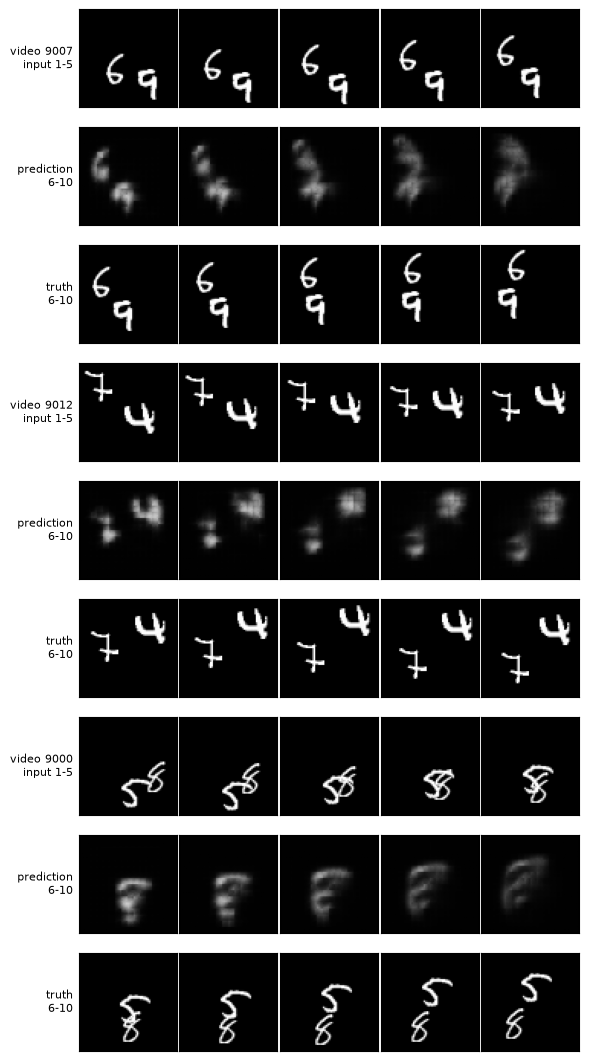

Figure 2 videos (dataset index): [9007, 9012, 9000] | overlapping: [9000]


In [12]:
# Figure 2: input, prediction and ground truth for three test videos (seed-0 model A)
def show_rows(rows, row_labels, path, col_titles=None, figsize_per=1.15):
    """rows: list of lists of 2-D arrays (None = blank cell)."""
    nr, nc = len(rows), max(len(r) for r in rows)
    fig, axes = plt.subplots(nr, nc, figsize=(figsize_per * nc, figsize_per * nr + 0.3), squeeze=False)
    for r, row in enumerate(rows):
        for c in range(nc):
            ax = axes[r, c]; ax.set_xticks([]); ax.set_yticks([])
            img = row[c] if c < len(row) else None
            if img is None:
                ax.axis("off")
            else:
                ax.imshow(img, cmap="gray", vmin=0, vmax=1)
            if c == 0:
                ax.set_ylabel(row_labels[r], rotation=0, ha="right", va="center", fontsize=8)
            if r == 0 and col_titles:
                ax.set_title(col_titles[c], fontsize=8)
    fig.tight_layout(pad=0.2); fig.savefig(path, bbox_inches="tight", dpi=150); plt.show()
 
FIG2_VIDEOS = [clean[0], clean[1], over[0]]          # change these indices if you prefer others
mA = load_model("A", 0)
rows, labels = [], []
for i in FIG2_VIDEOS:
    X, Y, _ = make_windows(TEST_DEV[i:i + 1], 1, 1)
    X, Y = to_float(X), to_float(Y)
    P = predict(mA, X)
    rows += [[X[0, j, 0].cpu() for j in range(5)], [P[0, j, 0].cpu() for j in range(5)],
             [Y[0, j, 0].cpu() for j in range(5)]]
    labels += [f"video {9000+i}\ninput 1-5", "prediction\n6-10", "truth\n6-10"]
show_rows(rows, labels, f"{OUT}/figures/fig2_examples.pdf")
print("Figure 2 videos (dataset index):", [9000 + i for i in FIG2_VIDEOS],
      "| overlapping:", [9000 + i for i in FIG2_VIDEOS if i in over])

In [13]:
# Figure 1 stays on the first 50 videos => supporting check for Q2.1 only.
def flow_angles(video_ids):
    out = []
    for v in video_ids:
        vid = TRAIN_U8[v, :, 0].numpy()
        for s in range(19):
            prev, nxt = vid[s], vid[s + 1]
            flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
            dx, dy = flow[..., 0], flow[..., 1]
            keep = (prev > 51) & (nxt > 51) & (np.sqrt(dx**2 + dy**2) > 0.5)
            out.append(np.degrees(np.arctan2(-dy[keep], dx[keep])) % 360.0)
    return np.concatenate(out)
 
a_first25, a_second25 = flow_angles(range(25)), flow_angles(range(25, 50))
print("noise level: TV(first 25 videos, next 25 videos) =", round(tv_distance(a_first25, a_second25), 4))
a500 = flow_angles(range(500))
h500, _ = np.histogram(a500, bins=dir_bins); h500 = h500 / h500.sum()
print("500 videos: max / min bin relative to uniform:", round(h500.max() * 18, 3), round(h500.min() * 18, 3))
print("500 videos: TV vs mirror:", round(tv_distance(a500, (180 - a500) % 360), 4),
      "| TV vs 90-deg rotation:", round(tv_distance(a500, (a500 + 90) % 360), 4))

noise level: TV(first 25 videos, next 25 videos) = 0.1835
500 videos: max / min bin relative to uniform: 1.269 0.682
500 videos: TV vs mirror: 0.0971 | TV vs 90-deg rotation: 0.1238
